In [150]:
import numpy as np
import pandas as pd

In [167]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

## 탐색적 데이터 분석(EDA)

### head() : 데이터 샘플 확인

In [168]:
train.head()

,id,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,3331,34.0,State-gov,177331,Some-college,10,Married-civ-spouse,Prof-specialty,Husband,Black,Male,4386,0,40.0,United-States,>50K
1,19749,58.0,Private,290661,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40.0,United-States,<=50K
2,1157,48.0,Private,125933,Some-college,10,Widowed,Exec-managerial,Unmarried,Black,Female,0,1669,38.0,United-States,<=50K
3,693,58.0,Private,100313,Some-college,10,Married-civ-spouse,Protective-serv,Husband,White,Male,0,1902,40.0,United-States,>50K
4,12522,41.0,Private,195661,Some-college,10,Married-civ-spouse,Transport-moving,Husband,White,Male,0,0,54.0,United-States,<=50K


### shape : 데이터 크기 확인

In [169]:
print("훈련 데이터 :", train.shape)
print("테스트 데이터 :", test.shape)

훈련 데이터 : (29304, 16)
테스트 데이터 : (3257, 15)


### info() : 자료형 확인

In [170]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29304 entries, 0 to 29303
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              29304 non-null  int64  
 1   age             29292 non-null  float64
 2   workclass       27642 non-null  object 
 3   fnlwgt          29304 non-null  int64  
 4   education       29304 non-null  object 
 5   education.num   29304 non-null  int64  
 6   marital.status  29304 non-null  object 
 7   occupation      27636 non-null  object 
 8   relationship    29304 non-null  object 
 9   race            29304 non-null  object 
 10  sex             29304 non-null  object 
 11  capital.gain    29304 non-null  int64  
 12  capital.loss    29304 non-null  int64  
 13  hours.per.week  29291 non-null  float64
 14  native.country  28767 non-null  object 
 15  income          29304 non-null  object 
dtypes: float64(2), int64(5), object(9)
memory usage: 3.6+ MB


### describe() : 기초통계량 확인(수치형)

In [171]:
train.describe()

,id,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,29304.000000,29292.000000,2.930400e+04,29304.000000,29304.000000,29304.000000,29291.000000
mean,16264.027880,38.553223,1.897488e+05,10.080842,1093.858722,86.744506,40.434229
std,9384.518323,13.628811,1.055250e+05,2.570824,7477.435640,401.518928,12.324036
min,0.000000,-38.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,8145.750000,28.000000,1.177890e+05,9.000000,0.000000,0.000000,40.000000
50%,16253.500000,37.000000,1.783765e+05,10.000000,0.000000,0.000000,40.000000
75%,24374.250000,48.000000,2.370682e+05,12.000000,0.000000,0.000000,45.000000
max,32560.000000,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


### describe(include='O') : 기초통계량 확인(범주형)

In [172]:
train.describe(include='O')

,workclass,education,marital.status,occupation,relationship,race,sex,native.country,income
count,27642,29304,29304,27636,29304,29304,29304,28767,29304
unique,8,16,7,14,6,5,2,41,2
top,Private,HS-grad,Married-civ-spouse,Prof-specialty,Husband,White,Male,United-States,<=50K
freq,20451,9449,13466,3683,11845,25022,19578,26240,22263


### isnull().sum() : 결측치 확인

In [173]:
train.isnull().sum()

id                   0
age                 12
workclass         1662
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1668
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week      13
native.country     537
income               0
dtype: int64

### value_counts() : 데이터 빈도 확인

In [174]:
train['income'].value_counts()

income
<=50K    22263
>50K      7041
Name: count, dtype: int64

## 결측치 처리

#### 결측치 컬럼 삭제 

In [175]:
m = train['workclass'].mode()[0]
train['workclass'] = train['workclass'].fillna(m)
test['workclass'] = test['workclass'].fillna(m)

m = train['native.country'].mode()[0]
train['native.country'] = train['native.country'].fillna(m)
test['native.country'] = test['native.country'].fillna(m)

train.isnull().sum()

id                   0
age                 12
workclass            0
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1668
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week      13
native.country       0
income               0
dtype: int64

### 결측치 표시 : 결측치를 X로 표시, 특수한 의미가 있는 것은 아니며 단순히 결측을 나타내는 유니크 값

In [176]:
train['occupation'] = train['occupation'].fillna('X')
test['occupation'] = test['occupation'].fillna('X')
train.isnull().sum()

id                 0
age               12
workclass          0
fnlwgt             0
education          0
education.num      0
marital.status     0
occupation         0
relationship       0
race               0
sex                0
capital.gain       0
capital.loss       0
hours.per.week    13
native.country     0
income             0
dtype: int64

### 결측치 채우기(범주형) 

<Axes: >

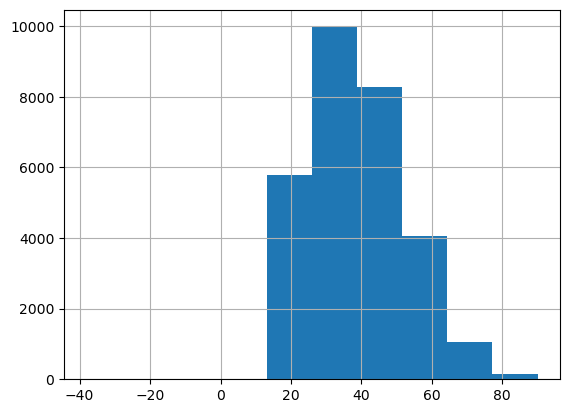

In [177]:
train['age'].hist()

In [178]:
#평균으로 결측치 채우기
value = int(train['age'].mean())
print("나이 평균 :", value)

train['age'] = train['age'].fillna(value)
test['age'] = test['age'].fillna(value)

나이 평균 : 38


<Axes: >

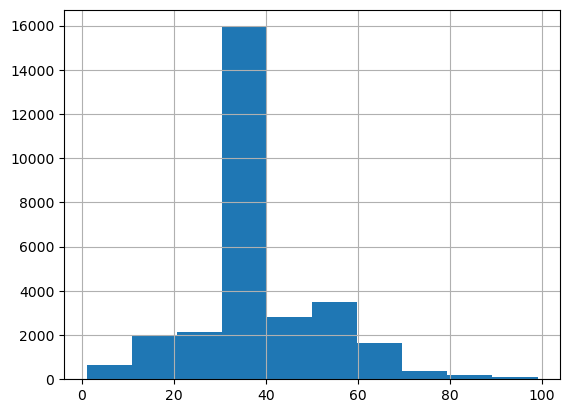

In [179]:
train['hours.per.week'].hist()

In [180]:
#중앙값으로 결측치 채우기
value = int(train['hours.per.week'].median())
print("중앙값 :", value)

train['hours.per.week'] = train['hours.per.week'].fillna(value)
test['hours.per.week'] = test['hours.per.week'].fillna(value) 

중앙값 : 40


### 이상치 제거

<Axes: >

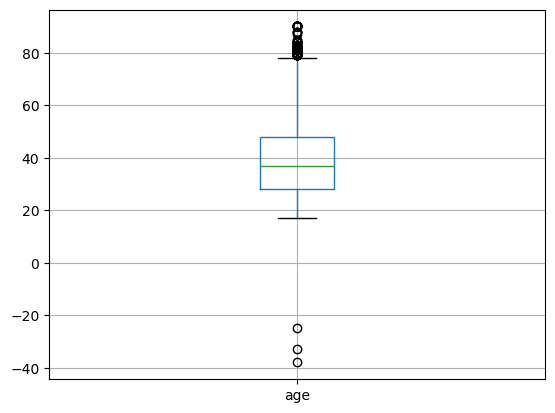

In [181]:
train.boxplot(column='age')

In [182]:
cond1 = train['age'] < 0
cond2 = test['age'] < 0

print("train 이상치 개수 :", sum(cond1))
print("test 이상치 개수 :", sum(cond2))

train = train[~cond1]
test = test[~cond2]

train 이상치 개수 : 3
test 이상치 개수 : 0


## 인코딩

In [183]:
#pop()으로 인코딩할 컬럼을 분리
y_train = train.pop('income')

### 원-핫 인코딩

In [184]:
train_oh = pd.get_dummies(train)
test_oh = pd.get_dummies(test)

print("train :", train.shape)
print("test :", test.shape)
print("train_oh :", train_oh.shape)
print("test_oh :", test_oh.shape)

train : (29301, 15)
test : (3257, 15)
train_oh : (29301, 107)
test_oh : (3257, 103)


#### 원-핫 인코딩 시 train데이터와 test데이터의 컬럼 수가 달라질 수 있다.
#### 이를 방지하기 위해 train데이터와 test데이터 병합 후 재분할 필요가 있다.

In [185]:
data = pd.concat([train,test],axis=0)
data_oh = pd.get_dummies(data)

train_oh = data_oh.iloc[0:len(train)].copy() #데이터프레임을 다른 변수로 옮길 때는 copy()를 붙여서 사본임을 명시하는 습관!!
test_oh = data_oh.iloc[len(train):].copy()

print("train :", train.shape)
print("test :", test.shape)
print("train_oh :", train_oh.shape)
print("test_oh :", test_oh.shape)

train : (29301, 15)
test : (3257, 15)
train_oh : (29301, 107)
test_oh : (3257, 107)


### 레이블 인코딩

In [186]:
from sklearn.preprocessing import LabelEncoder

In [187]:
cols = train.columns[train.dtypes == object]
cols

Index(['workclass', 'education', 'marital.status', 'occupation',
       'relationship', 'race', 'sex', 'native.country'],
      dtype='object')

In [188]:
test.isnull().sum()

id                0
age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
dtype: int64

In [189]:
for col in cols:
    le = LabelEncoder()
    train[col] = le.fit_transform(train[col])
    test[col] = le.transform(test[col])

train.head()

,id,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country
0,3331,34.0,6,177331,15,10,2,9,0,2,1,4386,0,40.0,38
1,19749,58.0,3,290661,11,9,2,2,0,4,1,0,0,40.0,38
2,1157,48.0,3,125933,15,10,6,3,4,2,0,0,1669,38.0,38
3,693,58.0,3,100313,15,10,2,10,0,4,1,0,1902,40.0,38
4,12522,41.0,3,195661,15,10,2,13,0,4,1,0,0,54.0,38


## 스케일링

In [191]:
cols = ['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']

### 민맥스 스케일링 : 최소값을 0, 최대값을 1로 스케일링

In [193]:
from sklearn.preprocessing import MinMaxScaler

In [192]:
##원본 데이터와의 비교를 위해 사본 생성
train_copy = train.copy()
test_copy = test.copy()

In [195]:
train_copy[cols].head()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
0,34.0,177331,10,4386,0,40.0
1,58.0,290661,9,0,0,40.0
2,48.0,125933,10,0,1669,38.0
3,58.0,100313,10,0,1902,40.0
4,41.0,195661,10,0,0,54.0


In [196]:
scaler = MinMaxScaler()

train_copy[cols] = scaler.fit_transform(train_copy[cols])
test_copy[cols] = scaler.transform(test_copy[cols])

train_copy[cols].head()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
0,0.232877,0.112092,0.600000,0.04386,0.000000,0.397959
1,0.561644,0.189060,0.533333,0.00000,0.000000,0.397959
2,0.424658,0.077184,0.600000,0.00000,0.383150,0.377551
3,0.561644,0.059785,0.600000,0.00000,0.436639,0.397959
4,0.328767,0.124541,0.600000,0.00000,0.000000,0.540816


### 스탠더드 스케일링 : 평균이 0, 표준편차가 1인 분포로 변환

In [197]:
from sklearn.preprocessing import StandardScaler

In [199]:
##원본 데이터와의 비교를 위해 사본 생성
train_copy = train.copy()
test_copy = test.copy()

In [200]:
train_copy[cols].head()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
0,34.0,177331,10,4386,0,40.0
1,58.0,290661,9,0,0,40.0
2,48.0,125933,10,0,1669,38.0
3,58.0,100313,10,0,1902,40.0
4,41.0,195661,10,0,0,54.0


In [201]:
scaler = StandardScaler()
train_copy[cols] = scaler.fit_transform(train_copy[cols])
test_copy[cols] = scaler.transform(test_copy[cols])

train_copy[cols].head()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
0,-0.335121,-0.117705,-0.031462,0.440247,-0.216056,-0.035121
1,1.428590,0.956277,-0.420430,-0.146298,-0.216056,-0.035121
2,0.693710,-0.604783,-0.031462,-0.146298,3.940528,-0.197450
3,1.428590,-0.847573,-0.031462,-0.146298,4.520806,-0.035121
4,0.179295,0.056001,-0.031462,-0.146298,-0.216056,1.101181


## 로버스트 스케일링 : 각 값의 중앙값을 빼고 IQR로 나누는 변환, 이상치에 덜 민감

In [202]:
from sklearn.preprocessing import RobustScaler

In [203]:
##원본 데이터와의 비교를 위해 사본 생성
train_copy = train.copy()
test_copy = test.copy()

In [204]:
train_copy[cols].head()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
0,34.0,177331,10,4386,0,40.0
1,58.0,290661,9,0,0,40.0
2,48.0,125933,10,0,1669,38.0
3,58.0,100313,10,0,1902,40.0
4,41.0,195661,10,0,0,54.0


In [206]:
scaler = RobustScaler()
train_copy[cols] = scaler.fit_transform(train_copy[cols])
test_copy[cols] = scaler.transform(test_copy[cols])

train_copy[cols].head()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
0,-0.15,-0.008711,0.000000,4386.0,0.0,0.0
1,1.05,0.941438,-0.333333,0.0,0.0,0.0
2,0.55,-0.439627,0.000000,0.0,1669.0,-0.4
3,1.05,-0.654423,0.000000,0.0,1902.0,0.0
4,0.20,0.144966,0.000000,0.0,0.0,2.8
